In [4]:
import tensorflow as tf
import cv2

import numpy as np
import matplotlib.pyplot as plt

In [5]:
print("TensorFlow:", tf.__version__)
print("OpenCV:", cv2.__version__)
print("NumPy:", np.__version__)

TensorFlow: 2.21.0
OpenCV: 4.11.0
NumPy: 2.5.1


In [6]:
from tensorflow.keras.models import load_model

model = load_model("driver_drowsiness_model.keras")

print("Model loaded successfully!")

Model loaded successfully!


In [7]:
eye_cascade = cv2.CascadeClassifier("haarcascade_eye.xml")

print("Eye detector loaded successfully!")

Eye detector loaded successfully!


In [8]:
import cv2

cap = cv2.VideoCapture(0)

ret, frame = cap.read()

print(ret)

cap.release()

True


In [9]:
ret, frame = cap.read()
print(ret)

False


In [10]:
import cv2

cap = cv2.VideoCapture(0)

while True:
    ret, frame = cap.read()

    if not ret:
        break

    cv2.imshow("Webcam Test", frame)

    # Press q to quit
    if cv2.waitKey(1) & 0xFF == ord('q'):
        break

cap.release()
cv2.destroyAllWindows()

In [11]:
import cv2

cap = cv2.VideoCapture(0)

while True:
    ret, frame = cap.read()

    if not ret:
        break

    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)

    eyes = eye_cascade.detectMultiScale(
        gray,
        scaleFactor=1.1,
        minNeighbors=5
    )

    for (x, y, w, h) in eyes:
        cv2.rectangle(frame,
                      (x, y),
                      (x + w, y + h),
                      (0, 255, 0),
                      2)

    cv2.imshow("Eye Detection", frame)

    if cv2.waitKey(1) & 0xFF == ord('q'):
        break

cap.release()
cv2.destroyAllWindows()

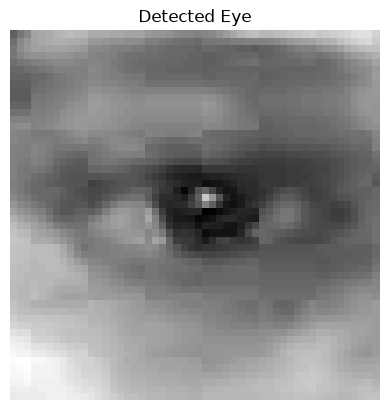

In [12]:
import cv2
import matplotlib.pyplot as plt

cap = cv2.VideoCapture(0)

ret, frame = cap.read()

gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)

eyes = eye_cascade.detectMultiScale(gray, 1.1, 5)

if len(eyes) > 0:
    x, y, w, h = eyes[0]     # Take the first detected eye

    eye = gray[y:y+h, x:x+w]

    plt.imshow(eye, cmap="gray")
    plt.title("Detected Eye")
    plt.axis("off")
    plt.show()

cap.release()

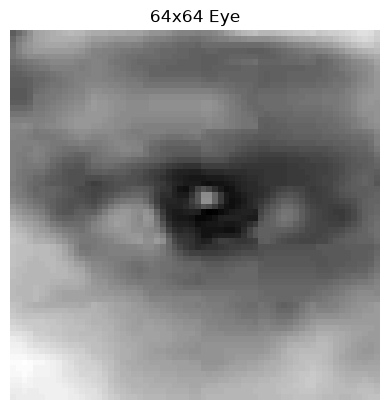

In [13]:
eye = cv2.resize(eye, (64, 64))

plt.imshow(eye, cmap="gray")
plt.title("64x64 Eye")
plt.axis("off")
plt.show()

In [14]:
eye = eye / 255.0

In [15]:
eye = eye.reshape(1, 64, 64, 1)

print(eye.shape)

(1, 64, 64, 1)


In [16]:
prediction = model.predict(eye)

print(prediction)

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
[[0.30001178 0.6999882 ]]


In [17]:
classes = ["awake", "sleepy"]

predicted_class = classes[np.argmax(prediction)]
confidence = np.max(prediction) * 100

print("Prediction :", predicted_class)
print("Confidence :", confidence)

Prediction : sleepy
Confidence : 69.99882


In [18]:
prediction = model.predict(eye)
print(prediction)

classes = ["sleepy", "awake"]

predicted_class = classes[np.argmax(prediction)]
confidence = np.max(prediction) * 100

print(predicted_class)
print(confidence)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 97ms/step
[[0.30001178 0.6999882 ]]
awake
69.99882


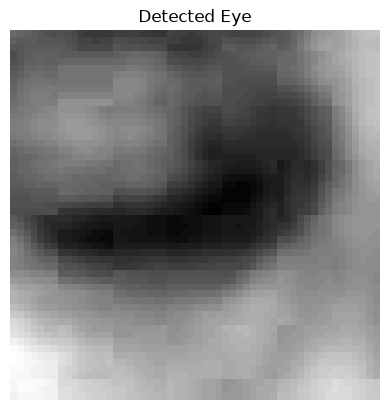

In [24]:
import cv2
import matplotlib.pyplot as plt

cap = cv2.VideoCapture(0)

ret, frame = cap.read()

gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)

eyes = eye_cascade.detectMultiScale(gray, 1.1, 5)

if len(eyes) > 0:
    x, y, w, h = eyes[0]     # Take the first detected eye

    eye = gray[y:y+h, x:x+w]

    plt.imshow(eye, cmap="gray")
    plt.title("Detected Eye")
    plt.axis("off")
    plt.show()

cap.release()

In [26]:
eye = eye / 255.0


In [27]:
eye = eye.reshape(1, 64, 64, 1)

print(eye.shape)

ValueError: cannot reshape array of size 2916 into shape (1,64,64,1)

In [28]:
print(eye.shape)

(54, 54)


In [29]:
eye = cv2.resize(eye, (64, 64))

In [30]:
print(eye.shape)

(64, 64)


In [31]:
eye = eye / 255.0

In [32]:
eye = eye.reshape(1, 64, 64, 1)

In [33]:
prediction = model.predict(eye)
print(prediction)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 83ms/step
[[0.4150272 0.5849728]]


In [34]:
prediction = model.predict(eye)
print(prediction)

classes = ["sleepy", "awake"]

predicted_class = classes[np.argmax(prediction)]
confidence = np.max(prediction) * 100

print(predicted_class)
print(confidence)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step
[[0.4150272 0.5849728]]
awake
58.49728


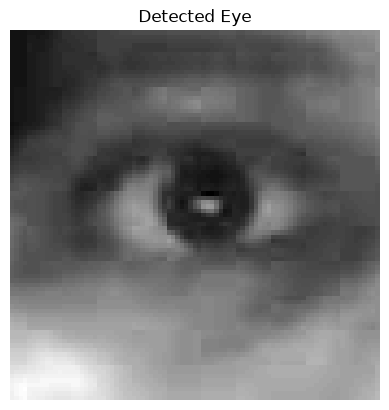

In [36]:
import cv2
import matplotlib.pyplot as plt

cap = cv2.VideoCapture(0)

ret, frame = cap.read()

gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)

eyes = eye_cascade.detectMultiScale(gray, 1.1, 5)

if len(eyes) > 0:
    x, y, w, h = eyes[0]     # Take the first detected eye

    eye = gray[y:y+h, x:x+w]

    plt.imshow(eye, cmap="gray")
    plt.title("Detected Eye")
    plt.axis("off")
    plt.show()

cap.release()

In [37]:
print(eye.shape)

(85, 85)


In [38]:
eye = cv2.resize(eye, (64, 64))

In [39]:
eye = eye / 255.0

In [41]:
print(eye.shape)

(64, 64)


In [42]:
eye = eye.reshape(1, 64, 64, 1)

In [43]:
prediction = model.predict(eye)
print(prediction)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step
[[0.30507034 0.6949296 ]]


In [44]:
prediction = model.predict(eye)
print(prediction)

classes = ["sleepy", "awake"]

predicted_class = classes[np.argmax(prediction)]
confidence = np.max(prediction) * 100

print(predicted_class)
print(confidence)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step
[[0.30507034 0.6949296 ]]
awake
69.49296
